In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

who = [
    # "BXII_S2",
    # "BXIII_S1", #: "BXIII_S1_23nM_SVs",
    "BXIII_S2", #: "BXIII_S2_60%_CSLB",
    "BXIII_S3", #: "BXIII_S3_3uM_Syn1",

    # "BXIII_S4", #: "BXIII_S4_15mM_LV4_4uM_Syn1",
    # "BXIII_S5", #: "BXIII_S5_15mM_LV4_6uM_Syn1",
    # "BXIII_S6", #: "BXIII_S6_15mM_LV4_6uM_Syn1_24uM_aSynWT",

    "BXIII_S11", #: "BXIII_S11_60%_CSLB_6uM_Syn1",
    "BXIII_S12", #: "BXIII_S12_60%_CSLB_4uM_Syn1",
    "BXIII_S13", #: "BXIII_S13_60%_CSLB_6uM_Syn1_12uM_aSynWT",
    "BXIII_S14", #: "BXIII_S14_60%_CSLB_6uM_Syn1_24uM_aSynWT",

    # "BXIV_S1", #: "BXIV_S1_15mM_LV4_6uM_Syn1_24uM_ATP",
    "BXIV_S3" #: "BXIV_S3_60%_CSLB_6uM_Syn1_24uM_ATP"
]

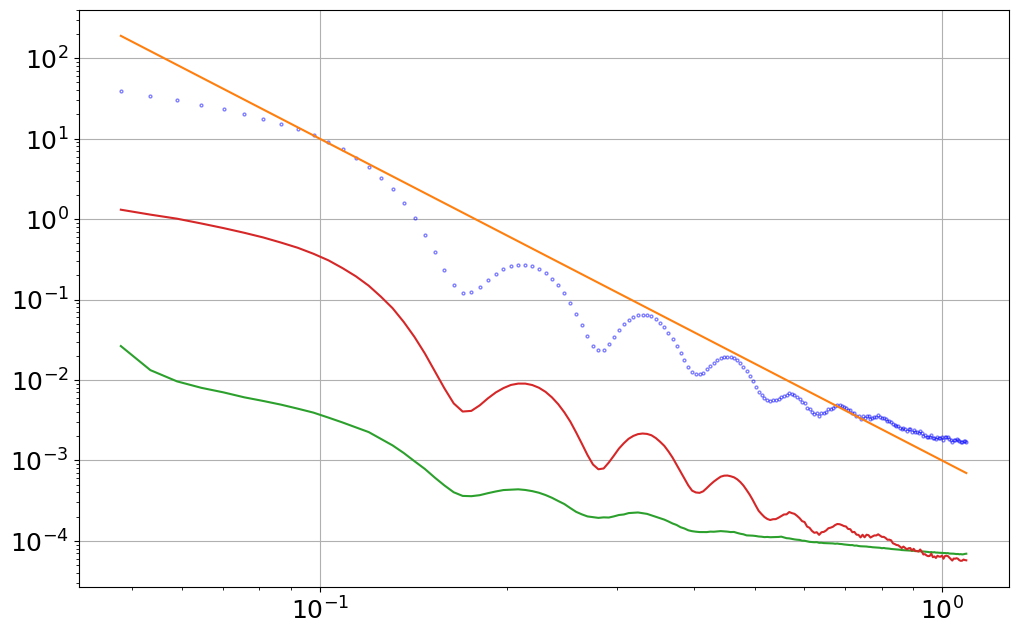

In [17]:
sample = "BXIII_S2"
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, I_err_Poisson = np.loadtxt(sub_dat_path, unpack=True)

mask = (q >= 0.00) & (q <= 1.1)
q    = q[mask]
I    = I[mask]
I_err_Poisson = I_err_Poisson[mask]
# Ierr = BM29.Poisson_error_focus_minimum_highq(q, I_err_Poisson)
plt.figure(figsize=(12, 7.5))
plt.loglog(q, I, marker="o", markersize=2, markeredgewidth=1, markeredgecolor='Blue', markerfacecolor='None', alpha=0.5, ls="None")
plt.loglog(q, q**(-4) * 1e-3)
plt.loglog(q, I_err_Poisson)
plt.loglog(q, I / 30)
plt.grid(True)
plt.show()

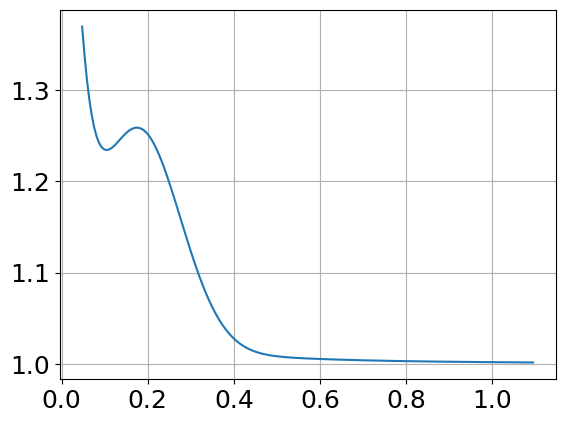

In [14]:
def structure_factor_single_peak(q, A, xi, D, s, P, q0, w):
    return (1 + A/(1+(xi*q)**2)                 # Lorentzian (Ornstein-Zernike)
              - D*np.exp(-q**2/(2*s**2))        # Gaussian centered at q = 0  
              + P*np.exp(-(q-q0)**2/(2*w**2))  # Gaussian at q₀, nearest-neighbour correlation peak
    )
A = 0.8     # A > 0 
xi = 20     # xi ≈ correlation length (~10–30 nm)
D = 0.2     # 
s = 0.15    # Width of the Gaussian centered at q = 0
P = 0.3     # Amplitude of the nearest-neighbour correlation peak
q0 = 0.17   # Position of the nearest-neighbour correlation peak
w = 0.1    # Width of the nearest-neighbour correlation peak

p0 = [A, xi, D, s, P, q0, w]
plt.plot(q, structure_factor_single_peak(q, *p0))
plt.grid(True)
plt.show()

[26.91, 1.662, 7.474e-09, 0.001673]
R = 25 (20, 35)
sigma_R = 4 (0, 8)
scale = 5.6e-09 (-inf, inf)
c4 = 0.001 (-inf, inf)
chi2_initial = 105.52
 
R_fit = 26.906 ± 0.064674
sigma_R_fit = 1.6616 ± 0.054071
scale_fit = 7.4739e-09 ± 1.381e-10
c4_fit = 0.0016729 ± 7.6863e-05
chi2 = 20.235


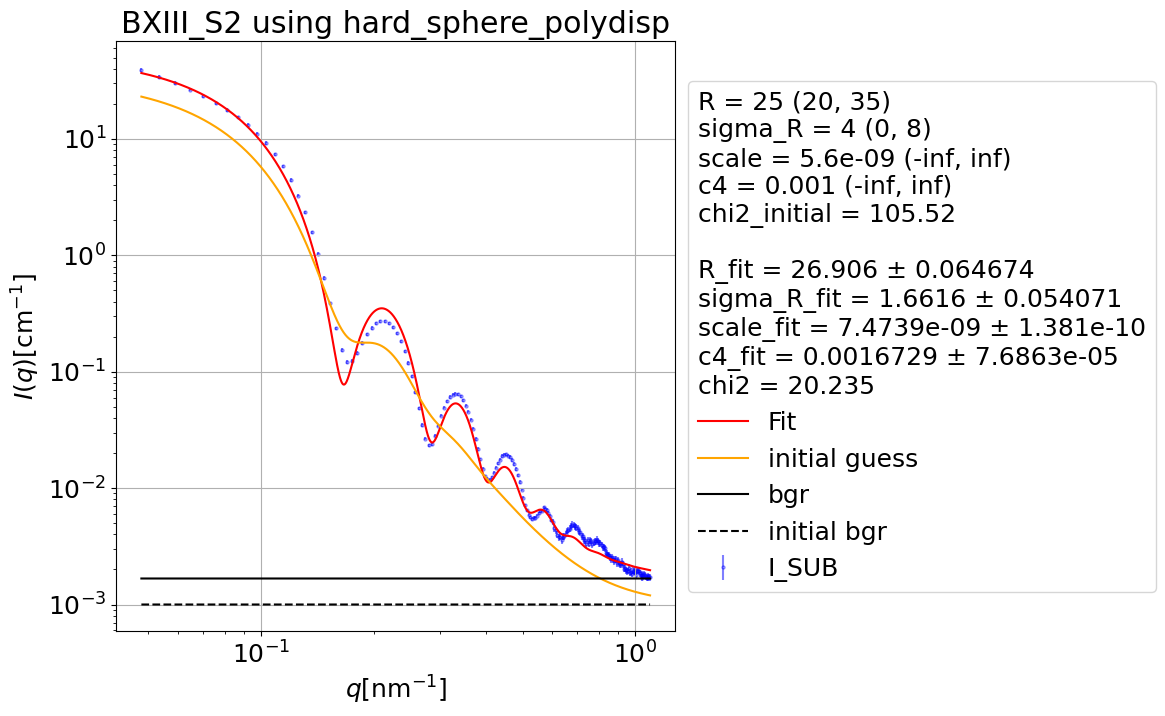

In [15]:
# hard_sphere_polydisp
fit_function_name = "hard_sphere_polydisp"
fit_function = lambda q, R, sigma_R, scale, c4: fit.hard_sphere_polydisp(q, R, sigma_R, scale, 0, 0, c4)
param_names = ["R_fit", "sigma_R_fit", "scale_fit", "c2_fit", "c3_fit", "c4_fit"]

sample = "BXIII_S2"
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, I_err_Poisson = np.loadtxt(sub_dat_path, unpack=True)

mask = (q >= 0.00) & (q <= 1.1)
q    = q[mask]
I    = I[mask]
I_err_Poisson = I_err_Poisson[mask]
I_err_op = I / 30
op_err_mask = q > 0.6
I_err_op[op_err_mask] = I[op_err_mask] / 15

q     = q
I     = I
I_err = I_err_op

# ========================== Parameters ==========================
R       = 25
sigma_R = 4
scale = 5.6e-9
c2 = 0
c3 = 0
c4    = 1e-3

# ========================== Setting Bounds ==============================
p0           = [   R,    sigma_R,     scale,           c4]
lower_bounds = [  20,          0,   -np.inf,      -np.inf]
upper_bounds = [  35,          8,   +np.inf,      +np.inf]

#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = ["R_fit", "sigma_R_fit", "scale_fit", "c4_fit"]

perr = np.sqrt(np.diag(pcov))
fit_lib_entry = "["
for name, value in zip(param_names, popt):
    globals()[name] = value
    fit_lib_entry += f"{value:.4g}, "
fit_lib_entry = fit_lib_entry[:-2]
fit_lib_entry += "]"
print(fit_lib_entry)
c2_fit, c3_fit = 0,0

chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
print(info_text_print)

#=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), 10000)
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,ecolor="Blue", markeredgecolor='Blue', markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='bgr')
plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [\\mathrm{nm}^{-1}]$')
plt.ylabel('$I(q) [\\mathrm{cm}^{-1}]$')
plt.title(f'{sample} using {fit_function_name}')
plt.grid(True)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)
plt.tight_layout()
# plt.savefig(target_folder / f"{sample}_hard_sphere_polydisp.png",dpi=400, bbox_inches='tight', pad_inches=0.05)
plt.show()

In [ ]:
# ellipsoid_homogen 
fit_function = fit.ellipsoid_homogen
param_names = ["R_fit", "sigma_R_fit", "eps_fit", "sigma_eps_fit", "scale_fit"]


In [ ]:
# hard_sphere_polydisp + DAB
fit_function = lambda q, R, sigma_R, scale, c4, c, xi: fit.hard_sphere_polydisp(q, R, sigma_R, scale, 0, 0, c4) + fit.DAB_model(q, c, xi)
param_names = ["R_fit", "sigma_R_fit", "scale_fit", "c4_fit", "c_fit", "xi_fit"]


In [ ]:
# ellipsoid_homogen + DAB
fit_function = lambda q, R, sigma_R, eps, sigma_eps, scale, c4, c, xi: fit.ellipsoid_homogen(q, R, sigma_R, eps, sigma_eps, scale, c4) + fit.DAB_model(q, c, xi)
param_names = ["R_fit", "sigma_R_fit", "eps_fit", "sigma_eps_fit", "scale_fit", "c4_fit", "c_fit", "xi_fit"]
